##### R1. Suppose the network layer provides the following service. The network layer in the source host accepts a segment of maximum size 1,200 bytes and a destination host address from the transport layer. The network layer then guarantees to deliver the segment to the transport layer at the destination host. Suppose many network application processes can be running at the destination host.

a. Design the simplest possible transport-layer protocol that will get application data to the desired process at the destination host. 
Assume the operating system in the destination host has assigned a 4-byte port number to each running application process.

* **設計考量：** 由於底層（網路層）已承諾提供保證送達的服務，因此在傳輸層的設計上，我們不需要實作如 TCP 那般複雜的可靠性傳輸機制（如：確認碼 ACK、計時器、重傳機制等）。
* **核心功能：** 傳輸層在此情境下唯一且最重要的任務，是將主機到主機 (Host-to-Host) 的通訊延伸為行程到行程 (Process-to-Process) 的通訊，也就是執行解多工 (Demultiplexing)。
* **標頭與酬載設計：** 作業系統已為每個應用程式行程分配了 4 位元組 (4-byte) 的埠號 。因此，我們設計的傳輸層區段 (Segment) 標頭只需要包含這 4 位元組的目的埠號 (Destination port number)即可 。
* **應用資料上限：** 由於網路層最大僅接受 1,200 位元組的區段，扣除 4 位元組的目的埠號標頭後，應用程式單次可傳送的最大資料量（Payload）為 1,196 位元組。

b. Modify this protocol so that it provides a "return address" to the destination process.

* **設計考量：** 為了讓接收端的應用程式知道該將回覆訊息送往何處，我們需要在封包內提供發送端的識別資訊，這在系統設計中稱為提供「回郵地址 (Return address)」。
* **核心功能擴充：** 傳輸層區段的標頭必須擴充，除了原本的 4 位元組目的埠號外，需再加入 4 位元組的來源埠號 (Source port number)。
* **標頭與酬載設計：** 更新後的傳輸層標頭總大小為 8 位元組（4 位元組來源埠號 + 4 位元組目的埠號）``。因此，扣除這 8 位元組的標頭開銷後，應用程式單次可傳送的最大資料量將縮減為 1,192 位元組 ``。

c. In your protocols, does the transport layer "have to do anything" in the core of the computer network?

* **核心架構原則：** 在計算機網路系統架構中，傳輸層**完全不需要**在網路核心（Network core，即中間的路由器）執行任何動作 。
* **實作位置：** 傳輸層協定僅實作於網路邊緣的「端系統 (End systems/Hosts)」中。
* **封包處理邏輯：** 中間的網路路由器僅依據網路層（如 IP）的標頭欄位來進行路由與轉發，它們既不會檢查，也不會修改或處理封裝在網路層資料報內部的傳輸層區段內容。這種將智慧與複雜度推向網路邊緣，而保持網路核心簡單的設計，正是網際網路架構中著名的端到端原則 (End-to-End Principle)之體現。

##### R2. Consider a planet where everyone belongs to a family of six, every family lives in its own house, each house has a unique address, and each person in a given house has a unique name. Suppose this planet has a mail service that delivers letters from source house to destination house. The mail service requires that (1) the letter be in an envelope, and that (2) the address of the destination house (and nothing more) be clearly written on the envelope. Suppose each family has a delegate family member who collects and distributes letters for the other family members. The letters do not necessarily provide any indication of the recipients of the letters.

首先列出對應關係

* 房屋 (Houses)：代表網路邊緣的端系統 (End systems) 或是主機 (Hosts)。
* 家庭成員 (Family members)：代表運行在主機上的各個應用程式行程 (Application processes)。
* 郵政服務 (Mail service)：代表提供主機到主機 (Host-to-Host) 傳輸服務的網路層 (Network layer) 與其底層路由基礎設施。
* 信封 (Envelope)：代表網路層的資料報 (Datagram)。
* 信件 (Letter)：代表應用層的訊息 (Application message) 或傳輸層的區段 (Transport-layer segment)。
* 家庭代表 (Delegate family member)：代表端系統作業系統內部的傳輸層協定 (Transport-layer protocol)。

a. Using the solution to Problem R1 above as inspiration, describe a protocol that the delegates can use to deliver letters from a 
sending family member to a receiving family member.

實作一套具備「多工 (Multiplexing)」與「解多工 (Demultiplexing)」功能的協定來完成精準派送：
* 發送端的「多工 (Multiplexing)」處理封裝：
    * 由於信件本身沒有提供收件者的指示，發送端的家庭代表在向家庭成員收集信件時，必須要求發信的成員提供「目標接收者的名字 (Destination Name)」，甚至可包含「發信者的名字 (Source Name)」以便對方回信。
    * 發送端代表必須在每一封信件的最上方（即傳輸層的標頭，Transport-layer header），明確寫上這個目標接收者的名字與發信者的名字。
    * 完成信件上的標頭註記後，發送端代表才會將信件放入信封中，並在信封外部（網路層標頭）寫上目的地的房屋地址，最後交給郵政服務。
* 接收端的「解多工 (Demultiplexing)」派送機制：
    * 當郵政服務將信封送達目的房屋後，接收端的家庭代表會拆開信封並取出信件。
    * 接收端代表會讀取信件最上方（傳輸層標頭）所註記的「目標接收者名字」。
    * 接收端代表接著會根據這個名字的指示，將信件精準地親手交給對應的那位家庭成員。在計算機網路中，這等同於傳輸層透過檢查區段中的目的埠號 (Destination port number)，將資料導向至正確的應用程式 Socket 介面。

b. In your protocol, does the mail service ever have to open the envelope and examine the letter in order to provide its service?

在這個通訊協定架構中，郵政服務（網路層）絕對不需要打開信封並檢查裡面的信件。
* 基於外部地址的純轉發機制 (Destination-based Forwarding)： 郵政服務（包含所有中間的郵差與郵政中心，即路由器 Routers）只需檢查寫在「信封外部」的房屋地址（即網路層資料報標頭中的目的 IP 位址）。郵政服務的唯一職責是將信封從來源房屋路由並轉發到目的房屋。
* 端到端原則 (End-to-End Principle) 的系統體現： 這種設計完美體現了計算機網路的端到端原則。傳輸層的邏輯（家庭代表的運作）僅實作於網路邊緣的端系統（房屋）內部。中間的網路路由器對於封裝在資料報內部的傳輸層區段（信封內的信件）毫無所知，它們既不會去檢查傳輸層的標頭欄位，也不會對應用層的資料進行任何操作。這種將複雜的應用派送邏輯保留在端系統，並讓網路核心保持簡單與純粹轉發的架構，正是網際網路得以高效擴展的核心關鍵。


##### R3. Consider a TCP connection between Host A and Host B. Suppose that the TCP segments traveling from Host A to Host B have source port number $x$ and destination port number $y$. What are the source and destination port numbers for the segments traveling from Host B to Host A?

當 TCP 區段從 Host B 傳送回 Host A 時，其**來源埠號 (Source port number) 將為 $y$**，而**目的埠號 (Destination port number) 將為 $x$**。

背後的架構原理：

* **回傳位址機制 (Return Address Mechanism)：** 在傳輸層的系統設計中，Host A 傳送至 Host B 的區段標頭內所包含的來源埠號 ($x$)，其核心作用就如同實體信件的回傳地址。當 Host B 準備傳送回覆區段給 Host A 時，Host B 的傳輸層會直接讀取 A-to-B 區段內的來源埠號數值，並將其作為 B-to-A 區段的目的埠號。
* **埠號的對稱反轉 (Inversion of Port Numbers)：** 傳輸層通訊雙方的端點呈現對稱反轉的設計關係。當資料反向流動時，發送端變成了 Host B 上處理該連線的應用程式行程（綁定於埠號 $y$），因此封包的來源埠號即為 $y$；而接收端變回了 Host A 當初發起連線的應用程式行程（綁定於埠號 $x$），因此目的埠號為 $x$。
* **確保精準的解多工 (Demultiplexing) 運作：** 透過這種來源與目的埠號對稱互換的機制，當 Host B 的封包抵達 Host A 時，Host A 的作業系統網路堆疊便能利用該目的埠號 ($x$)，搭配雙方的 IP 位址等資訊（即 TCP 連線的四元組），精準地將封包解多工 (Demultiplex) 並正確導向至 Host A 內部對應的 Socket 介面。


![](images/3.4.png)


##### R4. Describe why an application developer might choose to run an application over UDP rather than TCP.

在進行網路應用程式開發時選擇運行於 UDP 而非 TCP 之上，主要基於對傳輸效能、系統資源消耗與資料控制權等多面向的架構考量。


* **在應用層擁有更精細的資料傳送控制權 (Finer application-level control over what data is sent, and when)**
    在 UDP 協定中，一旦應用程式將資料傳遞給 UDP，UDP 會立即將其封裝成 UDP 區段並傳遞給網路層發送。相對地，TCP 具備壅塞控制 (Congestion control) 機制，當一條或多條網路鏈路發生壅塞時，TCP 會強制限制並節流 (Throttle) 傳送端的發送速率。此外，TCP 會持續重傳遺失的區段直到收到目的端的確認 (ACK) 為止，無論這會耗費多少時間。對於許多即時性應用 (Real-time applications) 而言，它們通常需要維持最低的發送速率，極度不希望傳輸受到過度延遲，且能夠容忍部分的資料遺失。因此，TCP 死板的服務模型並不完全符合這些應用的需求，開發者寧可選擇 UDP，並在應用層自行實作所需的額外控制功能。

* **無連線建立的延遲 (No connection establishment)**
    TCP 在開始傳輸資料之前，必須先執行三方交握 (Three-way handshake) 來建立連線。這個過程會引入額外的連線設定延遲。反觀 UDP 則不需任何正式的前置作業，直接就能發送資料 (Blasts away)。這正是為何 DNS (網域名稱系統) 通常運行於 UDP 之上的主因，因為若 DNS 使用 TCP，查詢將會變得非常緩慢。此外，現代的 HTTP/3 也採用了建構於 UDP 之上的 QUIC 協定，目的同樣是為了消除 TCP 連線建立所帶來的延遲。

* **無須維護連線狀態，大幅節省系統資源 (No connection state)**
    為了提供可靠傳輸與壅塞控制，TCP 必須在端系統 (End systems) 中維護複雜的連線狀態。這些狀態包含了接收與發送緩衝區 (Buffers)、壅塞控制參數，以及序號與確認號碼等參數。UDP 則完全不需要維護這些連線狀態與追蹤參數。從伺服器架構擴展的觀點來看，當特定的應用程式運行於 UDP 時，由於節省了龐大的記憶體與運算資源消耗，單一專屬伺服器通常能同時支援比 TCP 多出許多的活躍客戶端 (Active clients) 連線。

* **較小的封包標頭開銷 (Small packet header overhead)**
    在網路頻寬的利用率上，TCP 每個區段固定帶有 20 位元組 (Bytes) 的標頭開銷。而 UDP 的區段標頭僅有 8 位元組的微小開銷。對於需要頻繁發送小型資料的系統而言，UDP 能顯著降低無效控制標頭所佔用的網路頻寬比例。

* **即時多媒體應用的先天適配性與架構彈性 (Suitability for multimedia applications)**
    現代許多網路電話、即時視訊會議與串流影音等應用，可以容忍少量的封包遺失，因此 TCP 所提供的絕對可靠資料傳輸服務並非其成功的絕對必要條件。再者，這些即時應用對 TCP 的壅塞控制機制反應極差。因此，多媒體應用的開發者會選擇 UDP 來避免受到 TCP 壅塞控制的干擾。若應用程式確有特定程度的可靠性需求，開發者也能直接在應用層（基於 UDP）自行加入確認與重傳機制來打造專屬的可靠資料傳輸。這種架構設計使得應用程式能「魚與熊掌兼得 (Have its cake and eat it too)」，既能進行可靠通訊，又不會受制於 TCP 的傳輸速率限制。

##### R5. Why is it that voice and video traffic is often sent over TCP rather than UDP in today’s Internet? (Hint: The answer we are looking for has nothing to do with TCP’s congestion-control mechanism.)

現代網際網路中的語音與視訊（多媒體）流量經常選擇使用 TCP 而非 UDP，其最核心的原因與**網路安全策略及防火牆（Firewalls）限制**有關，而與 TCP 的壅塞控制機制無關。原因如下：

* **企業防火牆的預設阻擋策略 (Firewall Blocking Rules)：** 為了防範潛在的網路攻擊與提升內部網路安全性，許多組織與企業的網路管理員會將防火牆配置為嚴格攔截或阻擋大多數類型的 UDP 流量。
* **確保連線的成功穿透與備援機制 (Connectivity and Fallback)：** 如果語音或視訊應用程式僅依賴 UDP 進行傳輸，在遇到上述嚴格的防火牆環境時，將會導致封包被丟棄且通訊完全失敗。因此，網際網路電話 (Internet telephony) 與視訊會議等應用程式，通常會被設計為在 UDP 通訊失敗時，自動將 TCP 作為備用 (Backup) 傳輸協定，以確保能夠順利穿透防火牆並建立連線。
* **現代網路低遺失率提升 TCP 吸引力 (Low Packet Loss Rates)：** 雖然多媒體應用程式開發者傳統上為了避開 TCP 壅塞控制機制的干擾與封包標頭的額外開銷而偏好 UDP，但在現代網路基礎設施中，封包遺失率 (Packet loss rates) 普遍較低。在這種低遺失率的環境下，加上防火牆阻擋 UDP 流量的現實安全考量，使得 TCP 成為串流媒體傳輸時越來越具吸引力且務實的協定選擇。

Figure 3.6 是一個比較的證據。
> When packet loss rates are low, and with some organizations blocking UDP traffic for security reasons (see Chapter 8), TCP becomes an increasingly attractive protocol for streaming media transport.

##### R6. Is it possible for an application to enjoy reliable data transfer even when the application runs over UDP? If so, how?

是的，即使應用程式運行於 UDP 之上，依然可以實現可靠的資料傳輸 (Reliable Data Transfer)。


* **核心實作邏輯：將可靠性機制建構於應用層 (Application-Layer Reliability)**
    UDP 雖然本身是一個不可靠、無連線的傳輸層協定，但開發者可以跳過傳輸層的限制，直接在*應用程式*本身的程式碼內部自行實作所需的可靠性機制。(Transport Layer p.173)
* **具體的技術機制 (Specific Mechanisms)**
    應用程式可透過在應用層協定中自行加入*確認訊息 (Acknowledgments, ACKs)*與*逾時重傳 (Retransmissions)*等錯誤控制機制，來確保資料被正確地送達目的地。
* **現代網路架構的實際典範：QUIC 協定 (The QUIC Protocol)**
    現代網際網路中，QUIC (Quick UDP Internet Connections) 協定（現已應用於 HTTP/3）就是此概念最著名的實務範例。QUIC 底層完全使用無連線、不可靠的 UDP 進行封包傳遞，但將可靠資料傳輸 (RDT)、連線管理與壅塞控制等複雜機制，全部抽離並實作於應用層的子層 (Sub-layer) 之中。
* **系統設計的優勢 (Architectural Advantages)**
    透過這種將可靠性移至應用層的架構設計，應用程式能夠達到「魚與熊掌兼得 (Have its cake and eat it too)」的效果。這意味著系統既能確保端到端通訊的可靠性，又能避開傳統 TCP 寫死在作業系統核心中、較為死板的壅塞控制機制所造成的傳輸速率限制與干擾。

*(參考資料章節：Section 3.3 Connectionless Transport: UDP)*

##### R7. Suppose a process in Host C has a UDP socket with port number 6789. Suppose both Host A and Host B each send a UDP segment to Host C with destination port number 6789. Will both of these segments be directed to the same socket at Host C? If so, how will the process at Host C know that these two segments originated from two different hosts?

* **兩者會被導向至 Host C 的同一個 Socket**
    * 在傳輸層的底層架構設計中，UDP Socket 僅由一個*二元組 (Two-tuple)*來唯一識別，也就是：**(目的 IP 位址, 目的埠號)**。
    * 因此，即使這兩個 UDP 區段具有不同的來源 IP 位址（分別來自 Host A 與 Host B）或不同的來源埠號，只要它們的目的 IP 位址（Host C）與目的埠號（6789）完全一致，Host C 的傳輸層就會將這兩個 UDP 區段解多工 (Demultiplex)，並導向至**完全相同的 UDP Socket** 中。

* **Host C 的應用程式行程如何區分這兩個封包的來源**
    * 雖然封包進入了同一個接收佇列與 Socket，但 Host C 的應用程式絕對能夠精準區分它們。這是因為在網路通訊協定的設計中，每一個 UDP 區段的標頭都會帶有**來源 IP 位址 (Source IP address)**與**來源埠號 (Source port number)**。
    * 當 Host C 的應用程式行程從 Socket 讀取封包資料時（在系統網路程式設計中，這通常是透過呼叫 `recvfrom()` 方法來實現），作業系統的網路堆疊不僅會將封包的資料負載 (Payload) 傳遞給應用程式，同時也會一併提取並回傳該封包的來源 IP 位址與來源埠號給應用程式。
    * 藉由系統回傳的這些網路層與傳輸層來源資訊，Host C 的應用程式就能透過比對 IP 位址，明確得知哪一份資料來自 Host A、哪一份來自 Host B，並將這些來源位址當作後續發送回覆訊息時的*回郵地址 (Return address)*來使用。

##### R8. Suppose that a Web server runs in Host C on port 80. Suppose this Web server uses persistent connections, and is currently receiving requests from two different Hosts, A and B. Are all of the requests being sent through the same socket at Host C? If they are being passed through different sockets, do both of the sockets have port 80? Discuss and explain.

*   **不同主機的請求不會通過同一個 Socket：** 來自 Host A 與 Host B 的請求，**不會**被導向至 Host C 上的同一個 Socket。
*   **這兩個專屬 Socket 的目的埠號都會是 Port 80：** 是的，這兩個為了服務個別客戶端而建立的獨立連線 Socket，其目的埠號 (Destination Port) **都會是 80**。


* **TCP Socket 的四元組識別機制 (Four-tuple Identification)：** 
    與 UDP 僅依靠二元組不同，TCP 的 Socket 主要是透過一個*四元組*來進行唯一的連線識別與解多工 (Demultiplexing)。這四元組包含了：(來源 IP 位址、來源埠號、目的 IP 位址、目的埠號)。因為 Host A 與 Host B 必然擁有不同的來源 IP 位址，因此就算它們傳送的 TCP 區段擁有相同的目的 IP (Host C) 與目的埠號 (80)，Host C 的作業系統網路堆疊依然能透過這四個數值的差異，將封包精準導向至兩個截然不同的專屬 Socket。
* **Web 伺服器的動態 Socket 分配機制：** 
    在實際的網路伺服器維運中，Host C 上的 Web 伺服器會開啟一個 Port 80 的歡迎 Socket (Welcoming socket)來聆聽新的請求。當 A 與 B 進行三方交握時，系統便會為每一個客戶端分別建立一個全新的連線 Socket (Connection socket)。現代的高效能 Web 伺服器通常運用多執行緒 (Multi-threading) 架構，將這些不同但都關聯於 Port 80 的連線 Socket 交由不同的執行緒來處理。
*   **持續性連線 (Persistent Connections) 的系統行為：** 
    由於架構採用*持續性 HTTP (Persistent HTTP)*，這代表在該連線的生命週期尚未結束前，Host A 與 Host C 之間後續所有的 HTTP 請求與回應，都會不斷重複使用 Host A 專屬的同一個 Socket 進行資料交換；同樣的邏輯也適用於 Host B 與它專屬的 Socket。這樣便消除了頻繁建立與關閉 Socket 所造成的系統資源損耗。

![](images/3.5.png)

*(參考資料：第 3.2 節 Multiplexing and Demultiplexing)*

##### R9. In our rdt protocols, why did we need to introduce sequence numbers?

可靠資料傳輸（Reliable Data Transfer, rdt）協定中引入*序號（Sequence numbers）*是為了根除底層網路不穩定所引發的系統狀態模糊問題，具體來說是為了解決*重複封包（Duplicate packets）*的盲點。

* **ACK/NAK 損毀引發的重傳困境**：在設計 rdt2.0 時，我們利用確認訊息（ACK）與否定確認訊息（NAK）來回報接收狀態。但若這些回饋訊息在傳輸過程中發生位元損毀（Garbled），傳送端無從得知接收端是否正確收到資料。此時最安全的防呆設計就是直接重傳（Resend）該資料封包。
* **接收端的「狀態未知」盲區**：當傳送端盲目重傳時，會將「重複的封包」注入網路通道中。這對接收端造成了致命的邏輯問題：接收端無法事先知道剛抵達的封包，究竟是下一批「全新的資料」，還是因為前一次 ACK/NAK 損毀而導致的「重傳拷貝」。
* **序號機制的引入與精準識別**：為了解決這個狀態不同步的難題，架構上在資料封包的標頭中新增了*序號*欄位，讓傳送端為送出的每個封包進行編號。藉由這個機制，接收端只需要檢查封包的序號，就能精準判定該封包是否為重傳的重複封包。
* **系統資源的最佳化**：在基礎的停等式協定（Stop-and-wait protocol，如 rdt2.1 與 rdt3.0）中，由於傳送端必須等待前一個封包被確認後才能送出下一個，因此序號的設計極度輕量化，僅需要「1 個位元（0 或 1，即交替位元協定）」的空間就足以讓接收端辨識封包的新舊狀態。

*參考資料：第 3.4.1 節 Building a Reliable Data Transfer Protocol*

##### R10. In our rdt protocols, why did we need to introduce timers?

在可靠資料傳輸（Reliable Data Transfer, rdt）協定中引入計時器（Timers）機制的根本原因，是為了解決底層網路環境中無法避免的**封包遺失（Packet Loss）**問題。


* **偵測封包遺失 (Detecting Packet Loss)：** 當網路通道（如 rdt3.0 所面臨的真實環境）不僅會損毀位元，還會將整個封包丟棄時，傳送端發出的資料封包或接收端回傳的確認訊息（ACK）都有可能在網路中徹底消失。系統必須具備一種機制來判斷「何時」發生了封包遺失。
* **觸發重傳機制 (Triggering Retransmission)：** 由於傳送端無從得知封包是成功送達、正在排隊延遲還是已經遺失，系統設計上採用了等待時間的策略。傳送端透過啟動一個倒數計時器（Countdown timer），若在設定的時間內未收到接收端傳來的 ACK，計時器便會觸發逾時（Timeout）中斷，迫使傳送端直接重傳（Retransmit）該資料封包。
* **設定合理的等待閥值 (Judicious Time Value Selection)：** 理論上，傳送端等待的時間必須至少大於封包的往返延遲（Round-trip delay）加上接收端的處理時間。但在實務架構中，精確的延遲時間極難預估，因此架構師會設定一個合理的時間閥值；一旦超過這個時間，系統便合理推斷封包極有可能已經遺失，藉此儘早啟動錯誤恢復機制，避免系統無限期地空等。
* **處理極端延遲與重複封包的容錯：** 在網路壅塞時，封包可能只是經歷了極大的延遲而未遺失。此時計時器會引發*提早逾時（Premature timeout）*並進行重傳，導致網路中出現重複的封包。這也是為何 rdt 協定在引入計時器的同時，必須搭配*序號（Sequence numbers）*機制，讓接收端能夠順利過濾掉因計時器觸發而產生的重複拷貝。

![](images/3.15.png)
![](images/3.16.png)
*(參考資料：第 3.4.1 節 Building a Reliable Data Transfer Protocol)*

##### R11. Suppose that the roundtrip delay between sender and receiver is constant and known to the sender. Would a timer still be necessary in protocol rdt 3.0, assuming that packets can be lost? Explain.

即使發送端與接收端之間的來回延遲時間 (RTT) 是一個已知且固定的常數，在 rdt 3.0 協定中**依然絕對需要**使用計時器 (Timer)。

* **打破封包遺失造成的無限期空等 (Breaking the Deadlock of Packet Loss)：** 當網路通道中發生封包遺失時（無論是發送端的資料封包遺失，或是接收端回傳的 ACK 遺失），接收端不會有任何回應，發送端也將永遠無法收到對應的確認訊息。若沒有計時器，發送端將會陷入無限期等待的死結狀態。
* **必須具備觸發重傳的中斷機制 (Triggering Retransmission via Interrupts)：** 在計算機系統底層實作中，要實踐*等待一段特定時間以確認封包遺失*的邏輯，必須依賴*倒數計時器 (Countdown timer)*在時間到期時產生中斷 (Interrupt) 訊號。若拔除計時器，發送端系統將失去感知時間流逝的能力，進而無法主動觸發重新傳輸 (Retransmit) 動作。
* **已知的 RTT 僅改變計時器的閥值設定(Known RTT Only Optimizes the Timeout Value)：** 具備固定且已知的 RTT，其系統設計優勢在於不需要再使用複雜的演算法去動態估算逾時區間。可以直接將計時器的逾時閥值 (Timeout value) 精準設定為「已知的 RTT 加上接收端處理封包所需的時間」。換言之，已知 RTT 解決的是「計時器該設定多久」的問題，而無法消除計時器本身存在的必要性。


> rdt2.2 Sender 沒有計時器架構。因為底層不會掉包，Sender 只要發出封包，就採取死等（Stop-and-Wait）策略，直到收到接收端的 ACK 為止。
> rdt3.0 引入 Bit-Alternate Protocol。

![](images/3.15.png)
![](images/3.16.png)

*(參考資料：Section 3.4.1 Building a Reliable Data Transfer Protocol)*

> R12. Visit the Go-Back-N interactive animation at the companion Web site(https://computerscience.unicam.it/marcantoni/reti/applet/GoBackProtocol/goback.html).

> a. Have the source send five packets, and then pause the animation before any of the five packets reach the destination. Then kill the first packet and resume the animation. Describe what happens.

* **(a) 連續發送 5 個封包，並在抵達前丟棄第 1 個封包 (Kill the first packet)**
    * **動畫呈現現象：**
        * 第 1 個封包（pkt 0）被刪除消失。
        * 後續的第 2 到第 5 個封包（pkt 1, 2, 3, 4）仍會順利抵達接收端。
        * 接收端收到 pkt 1, 2, 3, 4 時，會直接將它們全部丟棄（Discard），並重複發送前一個正確收到的累積確認信號（即重複發送預期外的舊 ACK，或不推進接收視窗）。
        * 發送端針對 pkt 0 的計時器（Timer）超時（Timeout）。
        * 超時後，發送端會觸發「拉回重傳」，一口氣重新發送整個視窗內所有尚未被確認的 5 個封包（pkt 0, 1, 2, 3, 4）。

    * **情境描述：** 發送端將視窗內的 5 個封包送入網路，但第 1 個封包在傳輸過程中遺失。
    * **接收端系統行為：** 當後續的第 2、3、4、5 個封包順利抵達接收端時，由於第 1 個封包遺失，接收端會將這 4 個封包判定為「失序封包 (Out-of-order packets)」。GBN 的接收端設計原則是不會快取 (Buffer) 這些失序封包，因此會將它們**全部丟棄**，並對每一個被丟棄的封包重新回傳一次「最後一個正確接收的連續封包之 ACK」。
    * **發送端系統行為與結果：** 發送端在協議設計上，只會為「最早送出但尚未被確認的封包（即第 1 個封包）」維護單一一個計時器 (Single timer)。由於第 1 個封包已遺失，發送端將永遠等不到它的 ACK，最終導致該計時器發生逾時 (Timeout)。此時，GBN 的重傳機制會被觸發，發送端將會把「所有已送出但尚未被確認的封包」**全部重新傳送一次（即重傳封包 1 到 5）**。這展示了 GBN 協議在面對單一封包遺失時，所必須付出的大量重複傳輸效能代價。

> b. Repeat the experiment, but now let the first packet reach the destination and kill the first acknowledgment. Describe again what happens.

* **(b) 連續發送 5 個封包，封包皆抵達但丟棄第 1 個 ACK (Kill the first ACK)**
    * **動畫呈現現象：**
        * pkt 0 到達接收端，接收端成功接收並回傳 ACK 0，隨後該 ACK 0 被刪除。
        * 後續的 pkt 1, 2, 3, 4 陸續到達接收端，且因為是按序到達，接收端會正常依序接收，並分別回傳 ACK 1, ACK 2, ACK 3, ACK 4。
        * 發送端收到 ACK 1（或更後續的 ACK）時，發送視窗（Send Window）會直接向右大跨步滑動，pkt 0 與 pkt 1 同時被視為成功傳輸。
        * 網路完全不會發生計時器超時，也不會觸發任何重傳。
    * **情境描述：** 發送端送出 5 個封包，這 5 個封包皆依序成功抵達接收端。接收端也依序發出了 ACK 1 到 ACK 5，但途中的第 1 個 ACK (ACK 1) 發生遺失。
    * **系統行為與結果：** 發送端**不會**觸發任何重傳機制，系統將正常運作。
    * **原理解析：** 這是因為 GBN 採用的是*累積確認 (Cumulative acknowledgment)*架構。在累積確認機制的定義中，當接收端發出 ACK $n$ 時，代表序號 $n$ 及其之前的所有封包都已經被正確且依序地接收。因此，即使 ACK 1 在網路中遺失，只要發送端在計時器逾時之前收到了後續的 ACK（例如 ACK 2、ACK 3 等），發送端的系統就會自動判定前面的封包（包含第 1 個封包）皆已安全送達目的地。此時，發送端的傳輸視窗 (Sliding window) 會正常向前推進，展現了累積確認機制對於網路 ACK 遺失的高度容錯能力。

> c. Finally, try sending six packets. What happens?

* **(c) 嘗試連續發送 6 個封包 (Try sending six packets)**
    * **情境描述：** 在未收到任何 ACK 的狀態下，嘗試強行將第 6 個封包送入網路。
    * **系統行為與結果：** 發送端系統會**拒絕**送出第 6 個封包（在動畫中，點擊送出的按鈕將會無效或被忽略）。
    * **原理解析：** 該互動動畫的預設發送端「視窗大小 (Window size, $N$)」為 5。在 GBN 的狀態機 (FSM) 邏輯中，當應用層呼叫 `rdt_send()` 要求傳送資料時，傳輸層會先檢查目前視窗是否已滿（即未確認的封包數量是否已達上限 $N$）。由於前 5 個封包尚未收到任何確認，視窗空間已被耗盡，傳輸層會直接拒絕接收上層的新資料，直到收到早先封包的 ACK 並讓視窗向前滑動釋出空間為止。這體現了計算機網路設計中，傳輸層用來限制發送端注入網路資料量、避免網路雍塞崩潰的基礎流量控制閥門機制。

> R13. Repeat R12, but now with the Selective Repeat interactive animation(https://computerscience.unicam.it/marcantoni/reti/applet/SelectiveRepeatProtocol/selRepProt.html). How are Selective Repeat and Go-Back-N different?

針對選擇性重傳 (Selective Repeat, SR) 協定的運作機制與互動實驗，以下為您以系統架構的視角進行深度推演，並解析其與 Go-Back-N (GBN) 協定的核心架構差異：

選擇性重傳 (Selective Repeat) 的三種情境推演:

* **(a) 連續發送 5 個封包，並在抵達前丟棄第 1 個封包 (Kill the first packet)**
    * **接收端行為：** 在 SR 協定中，當第 1 個封包遺失時，接收端仍會正確接收後續到達的第 2、3、4、5 個封包。接收端會將這些失序 (Out-of-order) 的封包暫存在緩衝區 (Buffer) 中，並為它們分別回傳獨立的確認訊息 (ACK2 至 ACK5)。
    * **發送端行為：** 發送端為每個封包維護獨立的計時器。當第 1 個封包的計時器發生逾時 (Timeout) 時，發送端「僅會單獨」重新傳送遺失的第 1 個封包，而不會重傳已經被個別確認的後續封包。
    * **系統結果：** 當接收端收到重傳的第 1 個封包並補齊缺漏後，便會將這批連續的封包 (1 至 5) 一併交付 (Deliver) 給上層應用。
*   **(b) 連續發送 5 個封包，封包皆抵達但丟棄第 1 個 ACK (Kill the first ACK)**
    * **發送端行為：** 5 個封包皆抵達接收端，接收端分別發送 ACK1 到 ACK5，但 ACK1 遺失。由於 SR 不具備累積確認特性，發送端會認定封包 1 未成功送達。當封包 1 的專屬計時器逾時後，發送端會單獨重傳第 1 個封包。
    * **接收端行為：** 接收端收到重傳的封包 1 後，即使該封包的序號已落在當前接收視窗之前 (代表已接收並交付過)，根據 SR 接收端的狀態機邏輯，接收端仍必須再次產生並回傳一個 ACK1。這項防呆機制確保了發送端的視窗能順利向前滑動，避免系統死結。
*   **(c) 嘗試連續發送 6 個封包 (Try sending six packets)**
    * **系統行為：** SR 的發送端同樣受到最大允許未確認封包數量 (Window size, $N$) 的限制。若預設視窗大小為 5，在未收到任何 ACK 的情況下，發送視窗即宣告滿載。
    * **架構結果：** 傳輸層會拒絕接收上層應用的新資料或將其暫存，因此發送端無法將第 6 個封包送入網路，直到收到視窗內最舊封包的 ACK 並使視窗向前滑動為止。

Selective Repeat 與 Go-Back-N 的底層架構差異 (參考 3.4.3 與 3.4.4 節):

* **遺失重傳策略 (Retransmission Strategy)：** 
    * **GBN：** 採用包裹式重傳。當發生封包遺失與逾時，傳送端會重傳該遺失封包以及其後「所有」已發送但尚未被確認的封包。
    * **SR：** 採用按需重傳。傳送端僅會針對被判定為遺失或毀損的「單一封包」進行重新傳送，避免在網路錯誤率高或頻寬延遲乘積大的環境中產生大量不必要的重傳浪費。
* **確認機制 (Acknowledgment Mechanism)：** 
    * **GBN：** 採用「累積確認 (Cumulative acknowledgment)」。當發送 ACK $n$ 時，代表序號 $n$ 及其之前的所有封包皆已依序且正確地被接收。
    * **SR：** 採用「獨立確認 (Individual acknowledgment)」。接收端必須對每個正確接收的封包進行個別的 ACK 回報，無論該封包是否失序。
* **接收端快取與處理機制 (Receiver Buffering)：** 
    * **GBN：** 接收端設計極為輕量，不配置快取記憶體來儲存失序封包。若收到大於預期序號的封包，會直接將其丟棄，並回傳最高連續序號的 ACK。
    * **SR：** 接收端必須具備記憶體快取能力，將正確抵達但失序的封包暫存 (Buffered) 起來，等待遺失的封包補齊後，再依序一併交付給上層應用。
* **計時器系統架構 (Timer Architecture)：** 
    * **GBN：** 實務上僅需維護「單一計時器 (Single timer)」，通常用於追蹤傳送端發出最久且尚未被確認的封包。
    * **SR：** 需要為「每一個」傳送出去的封包維護獨立的邏輯計時器，以確保每個封包都能在逾時後被獨立重傳。
* **視窗同步狀態 (Window Synchronization)：** 
    * **GBN：** 由於不快取失序封包，發送端與接收端的視窗狀態與預期封包通常具備高度一致性。
    * **SR：** 由於接收端可能已經提前快取了落在視窗後段的失序封包，並已發送出對應的 ACK，因此在任何給定時間點，發送端與接收端的視窗並不總是重合的 (The sender and receiver windows will not always coincide)。

> R14. True or false?

> a. Host A is sending Host B a large file over a TCP connection. Assume Host B has no data to send Host A. Host B will not send acknowledgments to Host A because Host B cannot piggyback the acknowledgments on data.

False

* 即使 Host B 沒有任何應用層資料需要回傳給 Host A，Host B 的 TCP 傳輸層依然會發送「純確認 (Pure ACK)」區段給 Host A。
* 捎帶確認 (Piggybacking) 只是 TCP 為了節省頻寬的一種最佳化機制，當有反向資料要傳送時順便攜帶 ACK；但當沒有資料要傳送時，TCP 仍會產生一個資料負載為空（Empty data field）的區段來獨立傳遞 ACK。

*Section 3.5.2 TCP Segment Structure*

> b. The size of the TCP rwnd never changes throughout the duration of the connection.

False

* TCP 的接收視窗 rwnd (Receive Window) 是一個*動態 (Dynamic)*的變數，在連線期間會不斷改變。
* `rwnd` 的計算公式為 `RcvBuffer – [LastByteRcvd – LastByteRead]`。這代表 `rwnd` 取決於應用程式從接收緩衝區讀取資料的速度，以及網路底層資料抵達的速度；當緩衝區逐漸被填滿，`rwnd` 會縮小，當應用程式讀走資料，`rwnd` 則會擴大。

*Section 3.5.5 Flow Control*

> c. Suppose Host A is sending Host B a large file over a TCP connection. The number of unacknowledged bytes that A sends cannot exceed the size of the receive buffer.

True

* 這正是 TCP 流量控制 (Flow Control) 機制的最核心目標，也就是確保傳送端絕對不會傳送過多資料而導致接收端的緩衝區溢位。
* 根據 TCP 的狀態機控制法則，傳送端必須確保 `LastByteSent – LastByteAcked <= rwnd`。因為 `rwnd` 代表的是接收端緩衝區*當下剩餘的可用空間*，且其最大值不會超過 `RcvBuffer` (總接收緩衝區大小)，這保證了傳送端已送出但尚未被確認的位元組總數永遠不會大於接收緩衝區的上限。

*Section 3.5.5 Flow Control*

> d. Suppose Host A is sending a large file to Host B over a TCP connection. If the sequence number for a segment of this connection is $m$, then the sequence number for the subsequent segment will necessarily be $m + 1$ .

False

* TCP 的序號 (Sequence number) 系統是基於*位元組串流 (Byte-stream)*進行編號，而非基於「區段 (Segment)」的數量來編號。
* 區段的序號代表的是該區段資料負載中*第一個位元組*在整體資料流中的編號。因此，如果當前區段的序號為 $m$，且該區段夾帶了 $L$ 位元組的資料，那麼下一個區段的序號將會是 $m+L$，而不是 $m+1$。

*Section 3.5.2 TCP Segment Structure*

> e. The TCP segment has a field in its header for `rwnd`.

True

* TCP 標頭中確實存在一個專屬欄位用來乘載 `rwnd` 資訊。
* 在 TCP 的標準標頭架構中，包含了一個 16 位元 (16-bit) 的*接收視窗欄位 (Receive window field)*。接收端會透過這個欄位將當前的 `rwnd` 值主動通告 (Advertise) 給傳送端，藉此執行流量控制。

*Section 3.5.2 TCP Segment Structure*

> f. Suppose that the last SampleRTT in a TCP connection is equal to 1 sec. The current value of TimeoutInterval for the connection will necessarily be $\geq 1$ sec.

False

* `TimeoutInterval` 並非直接等於或絕對大於最新一次的測量樣本 `SampleRTT`。
* 逾時區間的計算公式為 `TimeoutInterval = EstimatedRTT + 4 * DevRTT`。其中 `EstimatedRTT` 是歷史樣本的*指數加權移動平均 (EWMA)*，舊樣本占有極大權重。假設連線過去的 RTT 都非常短（例如 0.1 秒），那麼即使最新一次的突發雜訊讓 `SampleRTT` 飆高到 1 秒，由於權重稀釋（平滑化）的關係，更新後的 `EstimatedRTT` 可能只有 0.2 秒左右。因此，最終算出的 `TimeoutInterval` 完全有可能小於 1 秒。

以下更詳細探討

* TCP 逾時區間的真實計算公式： TCP 的逾時區間並非直接套用最新一次的測量值，而是基於以下公式計算：`TimeoutInterval = EstimatedRTT + 4 * DevRTT`。這代表逾時區間是由平滑化後的估計 RTT加上 4 倍的 RTT 變異值所組成。
* EWMA (指數加權移動平均) 的平滑化效應： `EstimatedRTT` 是利用 `EWMA` 演算法計算出來的。其公式為：`EstimatedRTT = (1 - α) * EstimatedRTT + α * SampleRTT`，其中 RFC 6298 建議的 `α` 值為 0.125 (即 1/8)。這表示最新一次的 `SampleRTT` 權重只有 12.5%，而過去的歷史統計佔了高達 87.5% 的權重。
* 具體數值推演： 假設過去網路非常順暢，舊的 `EstimatedRTT` 一直維持在 100 毫秒 (0.1 秒)，`DevRTT` 為 10 毫秒。 現在網路突然發生一次極端的突發延遲，讓最新的 `SampleRTT` 飆高到 1000 毫秒 (1 秒)。 更新後的 `EstimatedRTT = 0.875 * 100ms + 0.125 * 1000ms = 87.5 + 125 = 212.5` 毫秒。 即使加上變異值 DevRTT 的影響，最終計算出來的 `TimeoutInterval` 也很可能落在 300~400 毫秒左右，遠小於 1 秒 (1000 毫秒)。
* 設計目的： 為什麼要這樣設計？因為真實網路環境中充滿了隨機的「雜訊」與「突發擁塞」。如果系統的逾時區間直接跟隨單一一次的極端 SampleRTT (例如 1 秒) 而劇烈拉長，一旦接下來發生封包遺失，TCP 傳送端將會白白浪費 1 秒鐘才啟動重傳，這會嚴重拖垮整體吞吐量效能。EWMA 的設計能確保 TCP 既能吸收偶發的延遲雜訊，又能穩健地反映長期的網路壅塞趨勢。

*Section 3.5.3 Round-Trip Time Estimation and Timeout*

> g. Suppose Host A sends one segment with sequence number 38 and 4 bytes of data over a TCP connection to Host B. In this same segment, the acknowledgment number is necessarily 42.

False

* 在全雙工 (Full-duplex) 的 TCP 系統中，一個區段內的*自身發送序號*與其夾帶的*確認序號 (Acknowledgment number)*是兩個完全獨立的計數器。
* Host A 在該區段填入的確認序號，代表的是 Host A 下一個「期望從 Host B 接收到的位元組序號」。這跟 Host A 自己正在送出的資料序號 (38) 以及自身資料長度 (4 bytes) 毫無關聯。

以下更詳細探討

* TCP 的全雙工 (Full-Duplex) 雙向獨立性： TCP 是一條全雙工的邏輯連線，這意味著「A 傳給 B 的資料流」與「B 傳給 A 的資料流」是兩條完全獨立的位元組串流 (Byte-stream)。因此，追蹤這兩條資料流的計數器（序號與確認號碼）也是完全獨立的。
* 序號 (Sequence Number)意義：在此區段中，Host A 的 Sequence Number = 38 且包含 4 bytes 資料。這代表 Host A 正在傳送其資料流中的第 38、39、40、41 號位元組。 對於 Host A 而言，數字 42 確實有意義，但它是 Host A「下一次」要傳送的序號，或者是 Host B 收到此區段後，回傳給 A 的「確認號碼」。
* 確認號碼 (Acknowledgment Number)意義：Host A 送出的區段中所夾帶的 Acknowledgment Number，代表的是 Host A 期望從 Host B 接收到的下一個位元組序號。 這個數值完全取決於 Host B 之前傳了多少資料給 Host A，與 Host A 自己現在傳出的資料長度 (38 + 4 = 42) 毫無任何數學與邏輯上的關聯。
* 捎帶確認 Piggybacking 機制： 在系統實作中，當 Host A 有資料要傳給 Host B 時，它會順便 (Piggyback)將它對 Host B 資料流的接收進度（即確認號碼）填入 TCP 標頭中。假設 Host B 之前已經傳送了 100 bytes (編號 0~99) 給 Host A 且 A 皆已正確接收，那麼 Host A 這次發出的區段標頭狀態將會是：
    * Sequence Number = 38 (A 自己的資料進度)
    * Data length = 4 bytes (A 傳送的負載)
    * Acknowledgment Number = 100 (A 催促 B 傳送第 100 號位元組) 


*Section 3.5.2 TCP Segment Structure*

> R15. Suppose Host A sends two TCP segments back to back to Host B over a TCP connection. The first segment has sequence number 90; the second has sequence number 110.

> a. How much data is in the first segment?

* 第一個區段包含 20 位元組 (bytes) 的資料
* 在 TCP 協定的底層設計中，序號系統是建立在*位元組串流 (Byte-stream)*之上，而非計算封包的數量。一個 TCP 區段的序號，代表的是該區段資料負載中*第一個位元組*在整體資料流中的編號。
* 由於第一個區段的序號為 90，而緊接在後發送的第二個區段序號為 110，這代表第一個區段佔用了從 90 號到 109 號的位元組。因此，其資料長度即為 110−90=20 位元組。

*第 3.5.2 節 TCP Segment Structure - Sequence Numbers and Acknowledgment Numbers*

> b. Suppose that the first segment is lost but the second segment arrives at B. In the acknowledgment that Host B sends to Host A, what will be the acknowledgment number?

* Host B 回傳的確認號碼將會是 90。
* TCP 採用的是*累積確認 (Cumulative acknowledgment)*機制。接收端在 TCP 標頭中填寫的確認號碼，永遠代表它*期望從發送端接收到的下一個依序 (in-order)*位元組的序號」。
* 在此情境中，由於第一個區段（包含位元組 90 到 109）在網路中遺失，Host B 的接收緩衝區中會出現資料空缺 (Gap)。即使 Host B 成功接收到了第二個區段（從位元組 110 開始的失序區段），在還未補齊 90 到 109 號位元組之前，Host B 仍然會持續等待第 90 號位元組的到來。因此，它會回傳一個確認號碼為 90 的 ACK 封包告訴 Host A 自己還在等待 90 號位元組（這在後續若持續收到其他失序封包時，會形成重複確認 Duplicate ACKs，進而觸發發送端的快速重傳機制）。

*第 3.5.2 節 Sequence Numbers and Acknowledgment Numbers, 第 3.5.4 節 Reliable Data Transfer*

> R16. Consider the Telnet example discussed in Section 3.5. A few seconds after the user types the letter `C,` the user types the letter `R.` After typing the letter `R,` how many segments are sent, and what is put in the sequence number and acknowledgment fields of the segments?

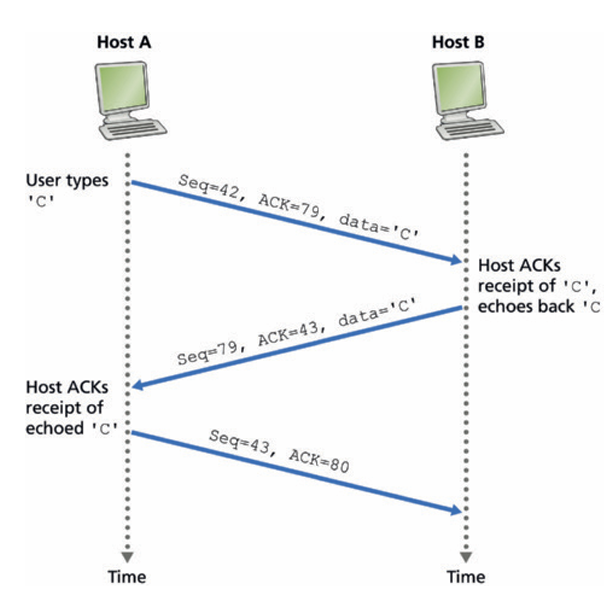

當使用者在數秒後輸入字母 `R` 時，系統底層**總共會產生並傳送 3 個 TCP 區段 (segments)**。

在解析這 3 個區段之前，我們必須先回顧系統在輸入字母 `C` 並完成互動後的狀態：
* Client 端的下一個發送序號已推進至 **43**。
* Client 端期望從 Server 端接收的下一個位元組序號（確認號碼）已推進至 **80**。
* Server 端的下一個發送序號已推進至 **80**。
* Server 端期望從 Client 端接收的下一個位元組序號（確認號碼）已推進至 **43**。

基於上述狀態，當輸入字母 `R` 後，會觸發以下 3 個區段的傳輸流程：

* **第一個區段 (由 Client 發送至 Server)：傳送應用層資料 `R`**
  * **Sequence Number (序號) = 43**：代表此區段資料負載的第一個位元組編號，接續先前完成的進度。
  * **Acknowledgment Number (確認號碼) = 80**：Client 告訴 Server，它目前期望從 Server 接收的下一個資料位元組編號是 80。
  * **Data (資料負載)**：夾帶字母 `R`（1 byte）。

* **第二個區段 (由 Server 發送至 Client)：確認收到 `R` 並「回顯 (Echo)」`R`**
  * **Sequence Number (序號) = 80**：這是 Server 端接下來要發送的資料位元組編號（前一次回顯字母 `C` 的序號是 79，長度 1 byte，因此這次從 80 開始）。
  * **Acknowledgment Number (確認號碼) = 44**：Server 藉由此欄位告知 Client，它已經成功收到序號 43 的 1 byte 資料（即字母 `R`），現在正等待序號 44 的資料到來。此動作稱為「捎帶確認 (Piggybacking)」。
  * **Data (資料負載)**：夾帶字母 `R`（1 byte），作為顯示在使用者螢幕上的回顯資料。

* **第三個區段 (由 Client 發送至 Server)：確認收到 Server 的回顯資料**
  * **Sequence Number (序號) = 44**：因為 Client 剛才送出了 1 byte 的資料（序號 43），所以它本身的計數器推進至 44。
  * **Acknowledgment Number (確認號碼) = 81**：Client 告知 Server，它已經成功收到序號 80 的回顯資料，現在正等待序號 81 的資料到來。
  * **Data (資料負載)**：為空 (Empty)。這是一個純確認區段 (Pure ACK)，不夾帶任何應用層資料。

*Section 3.5.2 TCP Segment Structure - Telnet: A Case Study for Sequence and Acknowledgment Numbers*

> R17. Suppose two TCP connections are present over some bottleneck link of rate $R$ bps. Both connections have a huge file to send (in the same direction over the bottleneck link). The transmissions of the files start at the same time. What transmission rate would TCP like to give to each of the connections?

當兩條 TCP 連線同時開始傳送大量檔案，並共用一條傳輸速率為 $R$ bps 的瓶頸鏈路 (Bottleneck link) 時，TCP 會傾向給予每條連線 $R/2 bps$ 的傳輸速率。

* TCP 壅塞控制的公平性設計 (Fairness)： 在網路系統架構中，一個理想的壅塞控制機制必須確保共用資源的公平分配。當有 $K$ 條 TCP 連線共用同一個瓶頸鏈路時，系統設計的目標是讓每條連線獲得約 $R/K$ 的平均傳輸速率，也就是讓每條連線取得相等的鏈路容量份額
。在本情境中連線數為 2，因此 TCP 的目標是給予各 $R/2$ bps 的資源。
* AIMD (加法增加、乘法減少) 演算法的收斂特性： TCP 採用 AIMD 演算法進行網路頻寬的探測與調節。當兩條連線共同運作時，只要未發生網路壅塞，兩者的壅塞視窗都會以相同的速率線性成長（即在圖表上沿著 45 度角方向增加）
。當兩條連線的總合傳輸速率超過瓶頸鏈路容量 $R$ 而導致路由器緩衝區溢位與封包遺失時，這兩條連線便會同時觸發乘法減少機制，將其傳輸速率減半。
* 動態平衡與資源共享： 這種反覆的「同步砍半、等量增加」的系統動態行為，會強迫這兩條連線的吞吐量軌跡不斷往中央的「公平分配線 (Equal capacity share line)」靠攏並自然收斂。因此，在長時間的穩定運作下，TCP 協定的底層數學與狀態機制會確保這兩條連線動態且平均地各佔用 $R/2$ bps 的頻寬。

*Section 3.7.4 Fairness*

> R18. True or false? Consider congestion control in TCP. When the timer expires at the sender, the value of `ssthresh` is set to one half of its previous value.

False

* **錯誤原因：** 當 TCP 發送端的計時器發生逾時 (Timeout，即系統判定發生封包遺失與網路壅塞) 時，狀態變數 `ssthresh` (Slow-start threshold，慢啟動門檻值) **絕對不是**設定為它`前一次數值的一半`，而是被設定為**發生壅塞當下，壅塞視窗 (`cwnd`, Congestion Window) 大小的一半**。
* **逾時觸發的系統重置機制 (Timeout Handling)：** 根據傳統 TCP (Classic TCP) 的壅塞控制演算法設計，一旦發生逾時事件，系統會為了挽救網路壅塞而執行以下兩項嚴格的控制動作：
    1. **更新門檻值：** 系統會將 `ssthresh` 變數更新為發生逾時當下 `cwnd` 數值的二分之一 (`cwnd / 2`)。
    2. *視窗重置與慢啟動：** 系統會將發送端的壅塞視窗 `cwnd` 強制降至 1 個最大區段大小 (1 MSS)，並重新啟動「慢啟動 (Slow Start)」階段。
* 為何要設定為 `cwnd` 的一半而非原本 `ssthresh` 的一半？因為 `cwnd` 代表的是*引發網路壅塞當下的實際傳輸負載量*。將 `ssthresh` 設為發生問題時 `cwnd` 的一半，能讓系統在接下來的重新探測中，於達到上次導致壅塞負載的一半時，便提早切換為較保守的*壅塞避免 (Congestion Avoidance)*模式。若依賴舊有的 `ssthresh`，將無法真實反映當下網路頻寬衰退的現況。

*Section 3.7.1 Classic End-End TCP Congestion Control*



> R19. In the discussion of TCP splitting in the sidebar in Section 3.7, it was claimed that the response time with TCP splitting is approximately 4. $RTT_{FE} + RTT_{BE} + processing time$ this claim.

TCP 分流架構下的回應時間 (Response Time) 為什麼約為 $4 \cdot RTT_{FE} + RTT_{BE} + \text{processing time}$。TCP 分流是一種常見於現代內容傳遞網路 (CDN) 與雲端負載平衡器的核心優化技術，其目的在於將一條長距離的 TCP 連線拆分為「Client 到鄰近前端伺服器 (Front-End, FE)」與「前端伺服器到後端伺服器 (Back-End, BE)」兩段獨立的 TCP 連線。

我們可以透過拆解 TCP 連線建立、HTTP 請求轉發、以及 TCP 慢啟動 (Slow Start) 的時間軸來精確證明這個公式：

*   **步驟一：建立 Client 與 FE 之間的 TCP 連線 (TCP Handshake)**
    *   Client 向鄰近的 FE 傳送 `SYN` 封包，FE 隨後回傳 `SYNACK` 封包。
    *   這個 TCP 三方交握的前兩個步驟，消耗了 **$1 \cdot RTT_{FE}$** 的時間。
*   **步驟二：發送請求與 BE 後端處理 (Request Forwarding & Backend Processing)**
    *   Client 接著送出 `ACK` 封包並夾帶 HTTP `GET` 請求。此封包單向傳輸到達 FE，耗時 **$0.5 \cdot RTT_{FE}$**。
    *   FE 收到請求後，會利用與 BE 之間**預先建立好、且處於最大壅塞視窗狀態的持續性 TCP 連線 (Persistent Connection)** 將請求直接轉發給 BE。
    *   BE 收到請求後，花費 **$\text{processing time}$** 的時間來處理與運算資料。
    *   BE 將產生好的回應資料送回 FE。從 FE 送出請求到接收到 BE 回應的這段網路往返，共耗時 **$1 \cdot RTT_{BE}$**。
    *   *【階段小結】至此，FE 完整收到回應資料的時間點為：$1.5 \cdot RTT_{FE} + RTT_{BE} + \text{processing time}$*。
*   **步驟三：FE 透過「慢啟動」將資料傳送給 Client (Data Delivery via Slow Start)**
    *   因為 Client 與 FE 之間是一條全新的 TCP 連線，FE 必須依照 TCP 慢啟動 (Slow Start) 演算法，從小視窗 (cwnd = 1 MSS) 開始傳送資料。
    *   根據典型的網頁物件大小模型，假設資料需要 3 個傳輸回合 (Window Flights) 才能傳送完畢：
        1.  **Flight 1 (1 MSS)**：FE 送出資料，等待 Client 回傳 ACK。來回耗時 **$1 \cdot RTT_{FE}$**。
        2.  **Flight 2 (2 MSS)**：FE 收到 ACK 後視窗翻倍，送出資料並等待 ACK。來回耗時 **$1 \cdot RTT_{FE}$**。
        3.  **Flight 3 (4 MSS)**：FE 送出最後一批資料，資料單向抵達 Client 即算完成下載。單向耗時 **$0.5 \cdot RTT_{FE}$**。
    *   *【階段小結】慢啟動資料傳輸階段總耗時為 $1 + 1 + 0.5 = \mathbf{2.5 \cdot RTT_{FE}}$*。
*   **總結算 (Total Response Time Calculation)**
    *   將上述三個階段的耗時加總：
        $1 \cdot RTT_{FE}$ (步驟一)
        $+ 0.5 \cdot RTT_{FE} + RTT_{BE} + \text{processing time}$ (步驟二)
        $+ 2.5 \cdot RTT_{FE}$ (步驟三)
    *   **總回應時間即為：$4 \cdot RTT_{FE} + RTT_{BE} + \text{processing time}$**。


* **TCP 分流的效能價值**：如果沒有使用 TCP 分流（即 Client 直接連線到遠端的 BE），相同的慢啟動與連線建立過程必須在長距離的端到端連線上進行。這將導致總回應時間變成 $4 \cdot (RTT_{FE} + RTT_{BE}) + \text{processing time}$，也就是 $4 \cdot RTT_{FE} + 4 \cdot RTT_{BE} + \text{processing time}$。
* **隔離延遲瓶頸**：透過 TCP 分流的架構設計，我們將最耗時的 TCP 三方交握與慢啟動過程，**「隔離」**在延遲極低的 Client-to-FE 網路區段 ($RTT_{FE}$) 中進行。因此，昂貴的跨國或長距離延遲 ($RTT_{BE}$) 只會在後端抓取資料時被懲罰一次 (1 倍)，而非傳統架構下的 4 倍。這項設計大幅縮短了整體網路應用的反應時間，也是現代內容傳遞網路能夠極速載入網頁的底層原理。

> P1. Suppose Client A initiates a Telnet session with Server S. At about the same time, Client B also initiates a Telnet session with Server S. Provide possible source and destination port numbers for

> a. The segments sent from A to S.

* 來源埠號 (Source port number)： 會由 Client A 的作業系統網路堆疊動態分配一個大於 1023 且未被使用的閒置埠號（假設為 $x$）。
* 目的埠號 (Destination port number)： 23。Telnet 是一個使用熟知埠號 (Well-known port number) 的應用層協定，其預設服務埠號為 23。

> b. The segments sent from B to S.

* 來源埠號： 同樣由 Client B 的作業系統動態且獨立分配一個閒置的埠號（假設為 $y$）。
* 目的埠號： 23。

> c. The segments sent from S to A.

* 來源埠號： 23。當伺服器回覆時，原先的目的埠號 (23) 會對稱反轉成為區段標頭的來源埠號。
* 目的埠號： $x$（即 Client A 最初發起連線時的來源埠號，在此作為回覆目標的位址使用）。

> d. The segments sent from S to B.

* 來源埠號： 23。
* 目的埠號： $y$（即 Client B 最初發起連線時的來源埠號）。

> e. If A and B are different hosts, is it possible that the source port number in the segments from A to S is the same as that from B to S?

是的，絕對可能。

* 因為 Client A 與 Client B 是獨立運作的兩台不同實體主機，它們的作業系統各自獨立運行埠號分配演算法。因此，兩者極有可能巧合地選擇了完全相同的數值（例如兩台主機都選擇了來源埠號 26145）。
* TCP 解多工 (Demultiplexing) 機制： 即使來源埠號與目的埠號完全相同，Server S 依然能夠正確分辨並將資料導向對應的 Socket。在 TCP 的底層系統設計中，連線 Socket 嚴格依賴一個「四元組 (Four-tuple)」來進行唯一識別，包含：(來源 IP 位址、來源埠號、目的 IP 位址、目的埠號)。由於 A 與 B 分屬不同主機，其「來源 IP 位址」必定不同，因此即使埠號發生碰撞，這兩個 TCP 連線的四元組特徵依然各自具備唯一性，不會在伺服器端造成混淆或封包誤送。


> f. How about if they are the same host?

否，不可能發生
* 若這兩個 Telnet 客戶端連線行程運行於同一台主機上，它們封包的「來源 IP 位址」將會完全相同，且它們連線的「目的 IP 位址」與「目的埠號 (23)」也完全一致。倘若此時作業系統又分配相同的「來源埠號」給這兩個行程，這兩條 TCP 連線的「四元組」將會變成完全一模一樣，導致底層網路堆疊無法進行解多工處理。
* 為了確保連線四元組的唯一性，使作業系統的網路堆疊能正確將收到的封包分派給正確的 Socket，主機作業系統在建立新的 Socket 時，會強制掃描並分配一個「目前未被該主機其他 Socket 使用」的可用埠號。因此，在同一台主機上併發的兩個 Telnet 連線，必定會被系統的 Socket 介面分配到截然不同的來源埠號。

*Section 3.2 Multiplexing and Demultiplexing*

> P2. Consider Figure 3.5. What are the source and destination port values in the segments flowing from the server back to the clients’ processes? What are the IP addresses in the network-layer datagrams carrying the transport-layer segments?

![](images/3.5.png)

圖 3.5 (Figure 3.5) 所描述的網路系統狀態，伺服器 B (Server B) 正同時處理來自用戶端主機 A (Host A) 的一個 HTTP 連線，以及用戶端主機 C (Host C) 的兩個 HTTP 連線。

當伺服器 B 將區段回傳給這三個用戶端行程時，其網路層 (IP 位址) 與傳輸層 (埠號) 的封裝數如下：

* 從伺服器 B (Server B) 回傳至主機 A (Host A) 的連線區段：
    * 來源埠號 (Source port)： 80 (因伺服器端運行 Web 服務，接收與回應皆透過 Port 80)。
    * 目的埠號 (Destination port)： 26145 (主機 A 發起該 HTTP 連線時所動態分配的來源埠號)。
    * 來源 IP 位址 (Source IP address)： B (伺服器 B 本身的 IP 位址)。
    * 目的 IP 位址 (Destination IP address)： A (主機 A 的 IP 位址)。
* 從伺服器 B (Server B) 回傳至主機 C (Host C) 的第一個連線區段：
    * 來源埠號 (Source port)： 80。
    * 目的埠號 (Destination port)： 26145 (主機 C 發起第一個 HTTP 連線時分配的來源埠號)。
    * 來源 IP 位址 (Source IP address)： B。
    * 目的 IP 位址 (Destination IP address)： C (主機 C 的 IP 位址)。
* 從伺服器 B (Server B) 回傳至主機 C (Host C) 的第二個連線區段：
    * 來源埠號 (Source port)： 80。
    * 目的埠號 (Destination port)： 7532 (主機 C 發起第二個 HTTP 連線時分配的來源埠號)。
    * 來源 IP 位址 (Source IP address)： B。
    * 目的 IP 位址 (Destination IP address)： C。


> P3. UDP and TCP use 1s complement for their checksums. Suppose you have the following three 8-bit bytes: 01010011, 01100110, 01110100. What is the 1s complement of the sum of these 8-bit bytes? (Note that although UDP and TCP use 16-bit words in computing the checksum, for this problem you are being asked to consider 8-bit sums.) Show all work. Why is it that UDP takes the 1s complement of the sum; that is, why not just use the sum? With the 1s complement scheme, how does the receiver detect errors? Is it possible that a 1-bit error will go undetected? How about a 2-bit error?

* **8 位元位元組的 1 的補數 (1s complement) 加總計算過程**
    根據 TCP/UDP 的錯誤檢測機制，我們將三個 8-bit 的資料進行相加，並在產生溢位 (Overflow/Carry) 時將其加回最低位元 (Wrap around)：
    * 第一位元組：`01010011`
    * 第二位元組：`01100110`
    * 第三位元組：`01110100`

    *步驟一：將前兩個位元組相加*
    ```text
      01010011
    + 01100110
    ----------
      10111001
    ```
    *步驟二：將上述結果與第三個位元組相加*
    ```text
      10111001
    + 01110100
    ----------
     100101101  (最左側產生了第 9 個位元的溢位 / Carry)
    ```
    *步驟三：將溢位位元加回結果的最低位元 (Wrap around)*
    ```text
      00101101
    +        1
    ----------
      00101110
    ```
    *步驟四：取 1 的補數 (將 0 變 1，1 變 0)*
    對 `00101110` 取 1 的補數，得到最終的 Checksum 值：**`11010001`**。

*   **為何 UDP 採用 1 的補數，而非直接使用總和 (Sum)？**
    在系統架構設計上，採用 1 的補數能讓接收端的驗證邏輯達到最高效率且設計極度簡化。如果傳送端傳遞的是「總和的 1 的補數」，接收端在進行錯誤檢查時，只需將收到的所有資料（包含 Checksum 本身）直接相加即可。若傳輸過程中沒有發生任何錯誤，加總的結果必然會是*全為 1*的位元串。這種設計使得系統無須在驗證時進行額外的減法或比對運算。

*   **接收端如何利用此機制偵測錯誤？**
    如同上述原理，接收端會將收到的所有 8-bit 字組以及 Checksum 一併相加（並處理溢位）。完成後，若結果為 `11111111`，則判定封包無誤；若該總和中有*任何一個位元為 0*，系統便會判定封包在傳輸或路由器儲存的過程中發生了位元損毀 (Bit errors)。

*   **1 個位元 (1-bit) 的錯誤有可能未被偵測到嗎？**
    **不可能。** 任何單一獨立位元的翻轉（例如某個 0 變成 1，或 1 變成 0）都會直接改變總和的結果，導致接收端在加總時，對應位置的位元無法得出 1，而是變成 0，從而100% 被系統偵測出來。

*   **2 個位元 (2-bit) 的錯誤有可能未被偵測到嗎？**
    **有可能。** 這是 Checksum 演算法在底層設計上的先天弱點。如果第一個位元組的某個位元從 0 翻轉成 1（數值增加），同時另一個位元組在「完全相同的位置」的位元從 1 翻轉成 0（數值減少），這兩個錯誤會在加總過程中互相抵消 (Cancel out)。在這種情況下，接收端算出的總和依然會是全為 1 的結果，導致這個 2-bit 錯誤完美避開偵測。這也是為什麼在對可靠度要求更高的資料鏈結層（Link layer）中，通常會改用更強大的循環冗餘檢查 (CRC) 來取代簡單的 Checksum。


> P4. 
> a. Suppose you have the following 2 bytes: 01011100 and 01100101. What is the 1s complement of the sum of these 2 bytes?

*  **(a) 計算 01011100 與 01100101 相加的 1 的補數**
    * **底層二進位加法：** 系統首先將這兩個 8-bit 的位元組進行相加。
        ```text
          01011100
        + 01100101
        ----------
          11000001
        ```
    * **溢位處理 (Wrap around)：** 在這次的相加中，最左側的最高位元並未產生溢位 (Carry out)，因此維持原結果 `11000001`。
    * **取 1 的補數：** 最後，網路堆疊會將加總結果的所有位元進行反轉（0 變 1、1 變 0）以產生 Checksum。`11000001` 取 1 的補數後，最終結果為 **`00111110`**。


> b. Suppose you have the following 2 bytes: 11011010 and 01100101. What is the 1s complement of the sum of these 2 bytes?

* **(b) 計算 11011010 與 01100101 相加的 1 的補數**
    * **底層二進位加法：** 將這兩個 8-bit 的位元組相加。
        ```text
          11011010
        + 01100101
        ----------
         100111111
        ```
    * **溢位處理 (Wrap around)：** 此計算產生了第 9 個位元的溢位（最左側的 1）。根據 1 的補數算術邏輯，必須將這個溢位加回到結果的最低位元。
        ```text
          00111111
        +        1
        ----------
          01000000
        ```
    * **取 1 的補數：** 對加回溢位後的結果 `01000000` 進行位元反轉，最終的 Checksum 結果為 **`10111111`**。

> c. For the bytes in part (a), give an example where one bit is flipped in each of the 2 bytes and yet the 1s complement doesn’t change.


* **(c) 各翻轉一個位元，但 1 的補數結果維持不變的範例**
    * **系統架構的盲點解析：** 這是 Checksum 錯誤檢測機制的先天設計弱點。如果在兩個不同的位元組中，**完全相同位置**的位元發生了「方向相反」的翻轉（例如一個從 0 變 1，另一個從 1 變 0），這兩個錯誤在加總計算時會互相抵消 (Cancel out)，導致最終總和與 1 的補數完全不變，進而使得錯誤無法被系統偵測出來。
    * **具體操作範例：** 以 (a) 題中的兩個位元組為例，我們選擇**最右側的位元 (LSB)** 進行翻轉。
        * **原始 Byte 1:** `01011100`
        * **原始 Byte 2:** `01100101`
        * **翻轉 Byte 1 (將最右側的 0 變 1)：** 變成 `01011101`
        * **翻轉 Byte 2 (將最右側的 1 變 0)：** 變成 `01100100`
    * **驗證抵消效應：** 將受到損毀的新位元組相加：
        ```text
          01011101
        + 01100100
        ----------
          11000001
        ```
        可以發現，加總結果依然是 `11000001`，其 1 的補數同樣維持 **`00111110`** 不變。這個 2-bit 的錯誤成功騙過了 UDP/TCP 的 Checksum 驗證機制。

*(參考資料：第 3.3.2 節 UDP Checksum)*


> P5. Suppose that the UDP receiver computes the Internet checksum for the received UDP segment and finds that it matches the value carried in the checksum field. Can the receiver be absolutely certain that no bit errors have occurred? Explain.


接收端絕對無法確信沒有發生位元錯誤。

* 系統設計的先天侷限 (Inherent Limitations of Error Detection)： 在網路通訊系統中，任何錯誤檢測與校正技術 (Error-detection and -correction techniques) 只能在一定機率下發現位元錯誤，但無法提供 100% 的絕對保證。這意味著即使封包附帶了錯誤檢測位元（如 Checksum），系統中依然可能出現「未被偵測到的位元錯誤 (Undetected bit errors)」，導致接收端在不知情的狀況下將損毀的資料交付給應用層。

* 1 的補數加總的錯誤抵消效應 (Error Cancellation in 1s Complement Sum)： UDP Checksum 的底層演算法，是將區段內的資料切割為多個 16 位元的字組 (16-bit words)，並對其進行 1 的補數加總 (1s complement sum)。若傳輸過程中發生了兩個（或多個）特定的位元翻轉，且這些翻轉在數學加總時「互相抵消」，Checksum 的驗證機制就會失效。

* 傳輸層檢測機制的強度取捨 (Trade-off in Transport Layer Error Protection)： 從系統架構的層次來看，Checksum 演算法的設計初衷是為了讓主機的作業系統能以純軟體的方式「快速且輕量」地執行運算。然而，這種輕量化的代價就是它提供的錯誤保護能力相對較弱 (relatively weak protection against errors)。若要應付更複雜或群聚發生的突發錯誤，通常必須仰賴底層資料鏈結層（硬體實作）所提供的循環冗餘檢查 (Cyclic Redundancy Check, CRC) 才能達到更高的偵錯率。

*Section 3.3.2 UDP Checksum*

> P6. Consider our motivation for correcting protocol rdt2.1. Show that the receiver, shown in Figure 3.58, when operating with the sender shown in Figure 3.11, can lead the sender and receiver to enter into a deadlock state, where each is waiting for an event that will never occur.

以系統設計與狀態機 (Finite-State Machine, FSM) 分析視角來看，rdt 2.1 協定中傳送端（Figure 3.11）與錯誤的接收端（Figure 3.58）之所以會陷入死結（Deadlock），是因為該接收端在底層邏輯上缺乏對*重複/失序封包*的例外處理機制。

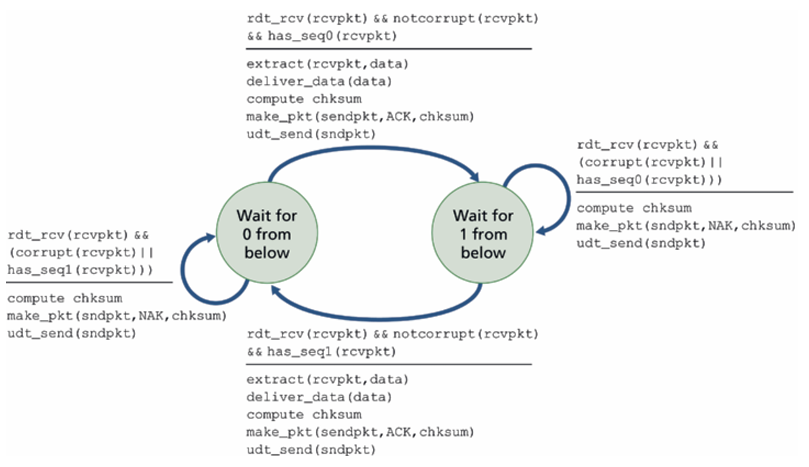

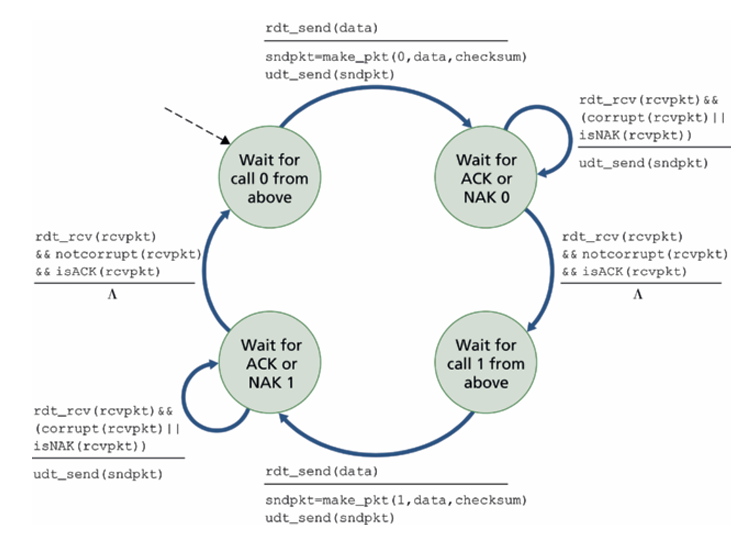

以下條列式推演系統陷入死結的完整過程：

*   **初始狀態與正常傳輸階段**
    *   **傳送端 (Sender)**：初始狀態為「等待上層呼叫 0 (Wait for call 0 from above)」。當應用層有資料需要傳送時，傳送端將資料封裝成序號為 0 的封包 (Packet 0) 並送入網路通道，隨後狀態轉移至「等待 ACK 或 NAK 0 (Wait for ACK or NAK 0)」。
    *   **接收端 (Receiver)**：初始狀態為「等待下方傳來 0 (Wait for 0 from below)」。成功且無誤地接收到 Packet 0 後，接收端會回傳確認訊息 (ACK 0)，並將狀態機推進至「等待下方傳來 1 (Wait for 1 from below)」。
*   **網路傳輸錯誤的觸發 (The Error Event)**
    *   假設接收端回傳的這份 ACK 訊息，在底層網路通道傳輸時發生了位元損毀 (Corrupted)。
*   **傳送端的防呆與重傳機制**
    *   傳送端在「等待 ACK 或 NAK 0」的狀態下收到了這份損毀的 ACK。根據 rdt 2.1 傳送端的 FSM 邏輯，只要收到損毀的封包或 NAK，系統為了確保可靠性，會直接「重新傳送」一次 Packet 0，並且**狀態依然保持不變**（繼續等待 ACK 0 或 NAK 0）。
*   **錯誤接收端的邏輯盲區 (The Logical Flaw)**
    *   此時，接收端的狀態機正處於「等待下方傳來 1」。然而，它實際收到的卻是傳送端剛剛重傳的 Packet 0（一個資料未損毀，但序號不符預期的舊封包）。
    *   在有缺陷的接收端設計中（如 Figure 3.58），設計者並未定義「當處於等待序號 1 時，卻收到正確的序號 0 封包」的狀態轉移規則。因為此封包既不符合受損條件（`corrupt(rcvpkt)`），也不符合序號 1 的預期條件（`has_seq1(rcvpkt)`），接收端的狀態機將不會觸發任何動作，也不會回傳任何 ACK，只能把封包丟棄並繼續停留在原狀態。
*   **系統陷入死結 (System Deadlock)**
    *   **傳送端**：無期限地停留在「等待 ACK 或 NAK 0」，因為接收端對重傳的 Packet 0 毫無反應，傳送端拿不到前進的許可。
    *   **接收端**：無期限地停留在「等待下方傳來 1」，因為傳送端在收到 ACK 0 之前，系統狀態不允許它送出新的 Packet 1。
    *   **缺乏中斷機制**：由於 rdt 2.1 協定架構中尚未引入「計時器 (Timers)」機制（計時器是在後續的 rdt 3.0 中才為了處理封包遺失而加入的硬體中斷防護），雙方將永遠互相等待對方不可能發生的事件，導致整個通訊協定徹底進入死結狀態。這也正是為何正確的 rdt 2.1 接收端（Figure 3.12）在收到重複的舊封包時，仍「必須強制回傳一次 ACK」的核心原因。

> P7. In protocol rdt3.0, the ACK packets flowing from the receiver to the sender do not have sequence numbers (although they do have an ACK field that contains the sequence number of the packet they are acknowledging). Why is it that our ACK packets do not require sequence numbers?

